# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

**Grupo:** Thiago Rivas, Juan Duarte y Agustín Occhiuzzi.

Los tres TODO están resueltos: el agente DQN (sección 6), los cortes de la política
(sección 10) y el estudio de ablación (sección 11). La discusión de los resultados
está en el informe.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib
# scipy se usa para el test estadístico de la sección 11
%pip install -q scipy
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\frand\Desktop\Facultad\AprendAut\laboratorioAprendAut1\.venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\frand\Desktop\Facultad\AprendAut\laboratorioAprendAut1\.venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
kernel: C:\Users\frand\Desktop\Facultad\AprendAut\laboratorioAprendAut1\.venv\Scripts\python.exe



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\frand\Desktop\Facultad\AprendAut\laboratorioAprendAut1\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.15.0+cpu | dispositivo: cpu


In [3]:
# Bibliotecas extra que usamos para los datos guardados, los cortes y el test
import copy
import base64
import io
import json
import zlib
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import stats

# Un solo hilo de PyTorch, igual que en las corridas del estudio
torch.set_num_threads(1)

## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [4]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 2
Estado siguiente: [ 0.004  1.426  0.217  0.344 -0.006 -0.067  0.     0.   ]
Recompensa: -2.497
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [5]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [6]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [7]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [8]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


### TODO 1: agente DQN

Red $8 \to 64 \to 64 \to 4$ con ReLU, memoria de repetición, red objetivo y
estrategia $\varepsilon$-greedy, como se explica en la sección II del informe. Los
valores por defecto son los de la configuración A0 (tabla I del informe).

In [9]:
# Implementación del agente DQN
class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Los valores por defecto son los de la configuración A0 del informe.
    Los tres interruptores `usar_...` sirven para las ablaciones de la sección 11.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 gamma=0.99,                     # descuento
                 lr=1e-3,                        # tasa de aprendizaje de Adam
                 tam_memoria=50_000,             # capacidad de la memoria de repetición
                 tam_lote=64,                    # transiciones por actualización
                 inicio_aprendizaje=1000,        # pasos antes de la primera actualización
                 aprender_cada=4,                # se actualiza la red cada 4 pasos
                 copiar_objetivo_cada=1000,      # pasos entre copias a la red objetivo
                 epsilon_inicial=1.0, epsilon_final=0.05,
                 episodios_epsilon=200,          # episodios en los que epsilon baja de 1 a 0.05
                 limite_gradiente=10.0,
                 usar_red_objetivo=True, usar_replay=True, usar_exploracion=True):
        # Semillas, para que dos corridas con la misma semilla den lo mismo
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)

        self.accion_space = accion_space
        self.gamma = gamma
        self.tam_lote = tam_lote
        self.inicio_aprendizaje = inicio_aprendizaje
        self.aprender_cada = aprender_cada
        self.copiar_objetivo_cada = copiar_objetivo_cada
        self.epsilon_inicial = epsilon_inicial
        self.epsilon_final = epsilon_final
        self.episodios_epsilon = episodios_epsilon
        self.limite_gradiente = limite_gradiente
        self.usar_red_objetivo = usar_red_objetivo
        self.usar_replay = usar_replay
        self.usar_exploracion = usar_exploracion

        # Sin exploración, epsilon queda en 0 desde el principio
        if usar_exploracion:
            self.epsilon = epsilon_inicial
        else:
            self.epsilon = 0.0
        self.pasos = 0
        self.episodios = 0
        self.memoria = deque(maxlen=tam_memoria)

        # Red Q: 8 entradas -> 64 -> 64 -> 4 salidas (un valor por acción)
        tam_estado = estado_space.shape[0]
        num_acciones = accion_space.n
        self.red_q = nn.Sequential(
            nn.Linear(tam_estado, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, num_acciones),
        )

        # Red objetivo: empieza como una copia de la red Q y no se entrena
        if usar_red_objetivo:
            self.red_objetivo = copy.deepcopy(self.red_q)
            self.red_objetivo.requires_grad_(False)

        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

    def elegir_accion(self, estado, explorar=True):
        """Elige acción; sin exploración si `explorar=False`."""
        # epsilon-greedy: con probabilidad epsilon, una acción al azar
        if explorar and self.usar_exploracion and random.random() < self.epsilon:
            return int(self.accion_space.sample())

        # Si no, la acción con mayor valor Q
        with torch.no_grad():
            estado_tensor = torch.tensor(estado, dtype=torch.float32).reshape(1, -1)
            valores_q = self.red_q(estado_tensor)
        return int(valores_q.argmax())

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""
        transicion = (np.array(estado, dtype=np.float32), int(accion), float(recompensa),
                      np.array(siguiente_estado, dtype=np.float32), bool(terminado))
        if self.usar_replay:
            self.memoria.append(transicion)
        self.pasos += 1

        # Se aprende cada `aprender_cada` pasos, después del calentamiento
        toca_aprender = (self.pasos >= self.inicio_aprendizaje
                         and self.pasos % self.aprender_cada == 0)
        if toca_aprender:
            if self.usar_replay:
                if len(self.memoria) >= self.tam_lote:
                    lote = random.sample(self.memoria, self.tam_lote)
                    self._actualizar_red(lote)
            else:
                # Sin replay: solo la transición que acaba de pasar
                self._actualizar_red([transicion])

        # Cada tanto, la red objetivo se pone al día copiando la red Q
        if self.usar_red_objetivo and self.pasos % self.copiar_objetivo_cada == 0:
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

    def _actualizar_red(self, lote):
        """Un paso de descenso por gradiente sobre un lote de transiciones."""
        estados, acciones, recompensas, siguientes, terminados = zip(*lote)
        estados = torch.tensor(np.stack(estados), dtype=torch.float32)
        acciones = torch.tensor(acciones, dtype=torch.int64).unsqueeze(1)
        recompensas = torch.tensor(recompensas, dtype=torch.float32)
        siguientes = torch.tensor(np.stack(siguientes), dtype=torch.float32)
        terminados = torch.tensor(terminados, dtype=torch.float32)

        # Q(s, a) que predice la red, solo para la acción que se tomó
        q_actual = self.red_q(estados).gather(1, acciones).squeeze(1)

        # Objetivo: z = r + gamma * (1 - d) * max_a' Q_objetivo(s', a')
        with torch.no_grad():
            if self.usar_red_objetivo:
                red_para_objetivo = self.red_objetivo
            else:
                red_para_objetivo = self.red_q
            q_siguiente = red_para_objetivo(siguientes).max(dim=1).values
            objetivo = recompensas + self.gamma * (1 - terminados) * q_siguiente

        # Pérdida de Huber, un paso de Adam y límite al tamaño del gradiente
        perdida = F.smooth_l1_loss(q_actual, objetivo)
        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.limite_gradiente)
        self.optimizador.step()

    def fin_episodio(self):
        """El bucle de entrenamiento lo invoca al terminar cada episodio."""
        self.episodios += 1
        if self.usar_exploracion:
            # epsilon baja en línea recta de 1 a 0.05 en 200 episodios y después queda fijo
            fraccion = min(self.episodios / self.episodios_epsilon, 1.0)
            epsilon = self.epsilon_inicial - (self.epsilon_inicial - self.epsilon_final) * fraccion
            self.epsilon = max(self.epsilon_final, epsilon)

## 7. Entrenamiento del agente DQN

Se entrena con la configuración A0 del informe: 300 episodios de hasta 1000 pasos,
sin parada temprana y con la semilla 42. Se usan 300 episodios en lugar de los 1200
sugeridos porque es el presupuesto común de todo el estudio: así se pudieron entrenar
los 32 agentes de la ablación con el mismo presupuesto, y el agente ya supera el 10% de
éxito pedido. Es la misma configuración y semilla que el
agente completo de semilla 42 del estudio. En la computadora donde se hizo esa corrida,
este entrenamiento da exactamente el mismo resultado; en otra puede dar un poco
distinto.

In [10]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)

print("\nEntrenando el agente DQN en LunarLander-v3...")
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=300,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)

env.close()


Entrenando el agente DQN en LunarLander-v3...


Episodio    15 | Recompensa media (100 ep):  -185.41 | Longitud media:   89.8 | epsilon: 0.929 |     0s


Episodio    30 | Recompensa media (100 ep):  -177.07 | Longitud media:   93.0 | epsilon: 0.858 |     1s


Episodio    45 | Recompensa media (100 ep):  -151.49 | Longitud media:   96.0 | epsilon: 0.786 |     2s


Episodio    60 | Recompensa media (100 ep):  -136.93 | Longitud media:   99.5 | epsilon: 0.715 |     3s


Episodio    75 | Recompensa media (100 ep):  -124.71 | Longitud media:  103.9 | epsilon: 0.644 |     5s


... (12 outputs left out)

Episodio   270 | Recompensa media (100 ep):    79.20 | Longitud media:  838.5 | epsilon: 0.050 |   110s


Episodio   285 | Recompensa media (100 ep):   103.91 | Longitud media:  789.5 | epsilon: 0.050 |   119s


Episodio   300 | Recompensa media (100 ep):   117.16 | Longitud media:  759.7 | epsilon: 0.050 |   128s


Tiempo total de entrenamiento: 128s


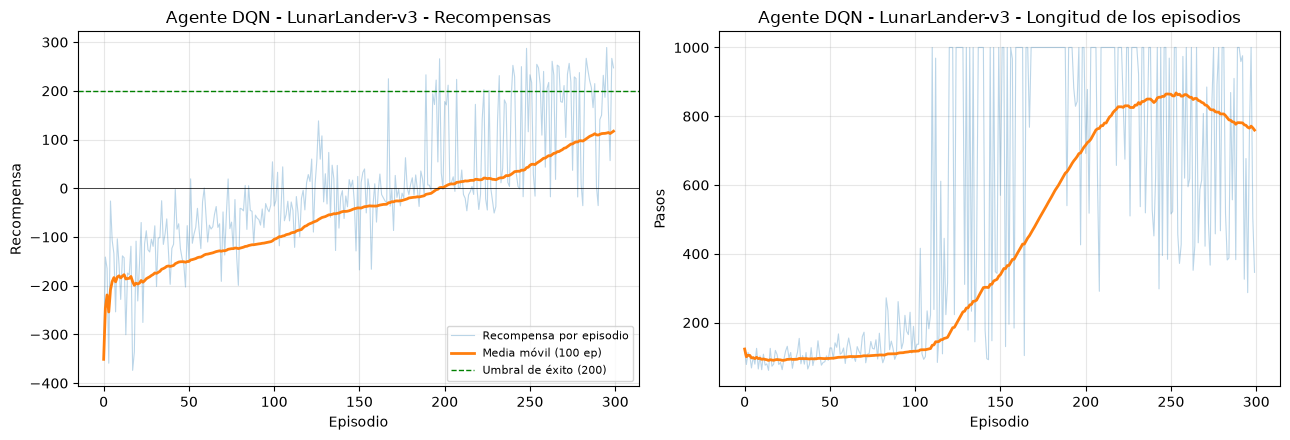

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 117.16
Tasa de éxito (R ≥ 200): 37.0%
Epsilon final: 0.050


In [11]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [12]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
# torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [13]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...



Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 34.0%
Recompensa promedio: 174.90
Recompensa mediana:  182.82
Desviación estándar: 76.90
Total de éxitos: 68 / 200

Implementación de referencia para comparar:



Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


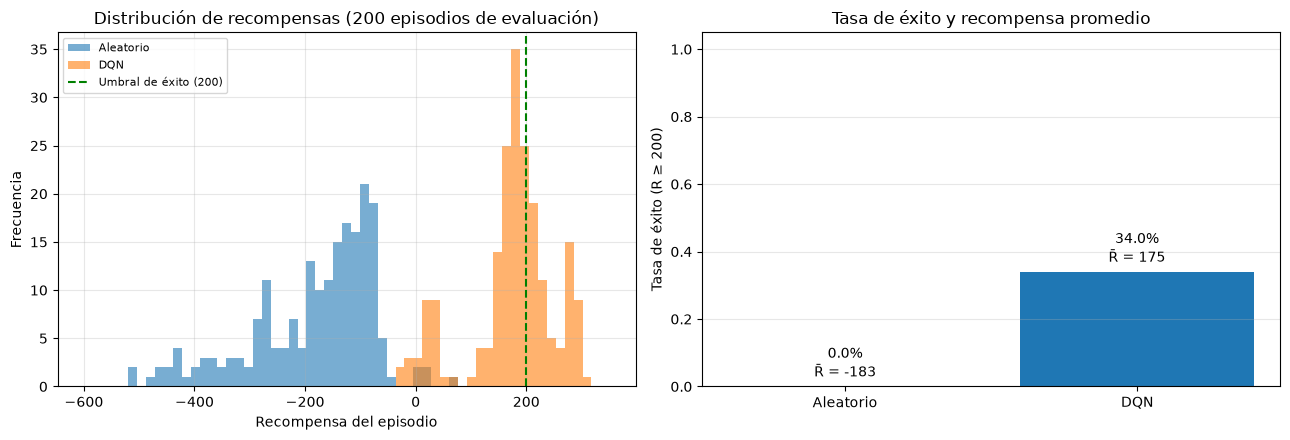

Tasa de éxito DQN:       34.0%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 358.1 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  34.0%
  R ≥  150:  78.5%
  R ≥  100:  86.0%
  R ≥    0:  96.5%
  Episodios que se estrellan (R < -50): 0.0%


In [14]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## Datos guardados de las corridas

La calibración y el estudio de ablación (32 agentes) se corrieron antes, en las
computadoras de los integrantes. Para que el notebook no dependa de otras carpetas,
en la celda siguiente están guardados, comprimidos, los retornos de entrenamiento y
de evaluación de esas corridas y los pesos finales de los ocho agentes completos.
Con esos datos se arman las tablas de la calibración y de las secciones 10 y 11.

In [15]:
# Datos de las corridas: JSON comprimido con zlib y pasado a texto con base64
texto_datos = '...'
datos_comprimidos = base64.b64decode(texto_datos)
datos = json.loads(zlib.decompress(datos_comprimidos))

print('Agentes del estudio de ablación:', len(datos['corridas']))
print('Corridas de calibración:', len(datos['calibracion']))

Agentes del estudio de ablación:

 32
Corridas de calibración: 8


### Calibración de hiperparámetros

Corresponde a la sección III del informe. Primero se compararon cuatro
configuraciones de la red y de la tasa de aprendizaje (A0 a A3), con las semillas 42
y 1042, 300 episodios de entrenamiento y 200 de evaluación.

In [16]:
# Retorno medio de evaluación de cada configuración y semilla
calibracion = sorted(datos['calibracion'], key=lambda c: (c['config'], c['semilla']))
medias_por_config = {}

print('Config | Capas      | lr     | Semilla | Retorno medio')
for corrida in calibracion:
    nombre = corrida['config']
    media = np.mean(corrida['evaluacion'])
    if nombre not in medias_por_config:
        medias_por_config[nombre] = []
    medias_por_config[nombre].append(media)
    capas = str(corrida['capas'])
    print(f"{nombre:6s} | {capas:10s} | {corrida['lr']:.4f} | {corrida['semilla']:7d} | {media:8.1f}")

print()
for nombre in medias_por_config:
    print(f"{nombre}: media de las dos semillas = {np.mean(medias_por_config[nombre]):.1f}")

Config | Capas      | lr     | Semilla | Retorno medio
A0     | [64, 64]   | 0.0010 |      42 |    167.2
A0     | [64, 64]   | 0.0010 |    1042 |    209.8
A1     | [128, 128] | 0.0005 |      42 |    142.1
A1     | [128, 128] | 0.0005 |    1042 |     33.7
A2     | [64, 64]   | 0.0005 |      42 |     -7.4
A2     | [64, 64]   | 0.0005 |    1042 |      7.7
A3     | [64, 64]   | 0.0050 |      42 |    203.3
A3     | [64, 64]   | 0.0050 |    1042 |     99.9

A0: media de las dos semillas = 188.5
A1: media de las dos semillas = 87.9
A2: media de las dos semillas = 0.1
A3: media de las dos semillas = 151.6


Antes se había probado el tamaño de la memoria de repetición en el notebook
`LunarLander_DQN_B.ipynb` (sección 8b), con la semilla 42, 500 episodios de
entrenamiento, 50 de evaluación y una red 128/128. Esos resultados se copian acá:

In [17]:
# Resultados de la prueba de replay de LunarLander_DQN_B.ipynb (sección 8b)
prueba_replay = [
    ('memoria de 100000', 247.7, 0.86),
    ('memoria de 10000', 223.6, 0.80),
    ('sin replay', -87.7, 0.00),
]
for nombre, retorno, exito in prueba_replay:
    print(f"{nombre:18s} | retorno medio {retorno:7.1f} | éxito {exito:.0%}")

memoria de 100000  | retorno medio   247.7 | éxito 86%
memoria de 10000   | retorno medio   223.6 | éxito 80%
sin replay         | retorno medio   -87.7 | éxito 0%


También se probaron formas de bajar $\varepsilon$, con cinco semillas, 600 episodios
de entrenamiento y 100 de evaluación (red 128/128, actualización suave de la red
objetivo y $\varepsilon$ mínimo de 0,01). Se compara la bajada exponencial contra la
lineal con el test de Mann–Whitney.

In [18]:
# Retorno medio de evaluación por semilla, agrupado por esquema de exploración
medias_exploracion = {}
for corrida in datos['exploracion']:
    esquema = corrida['esquema']
    if esquema not in medias_exploracion:
        medias_exploracion[esquema] = []
    medias_exploracion[esquema].append(np.mean(corrida['evaluacion']))

for esquema in medias_exploracion:
    print(f"{esquema:16s}: retorno medio {np.mean(medias_exploracion[esquema]):.1f}")

exponencial = medias_exploracion['exponencial']
lineal = medias_exploracion['lineal']
resultado = stats.mannwhitneyu(exponencial, lineal, alternative='two-sided')
print(f"\nMann-Whitney, exponencial contra lineal: p = {resultado.pvalue:.4f}")

exponencial     : retorno medio 177.1
lineal          : retorno medio 127.1
sin_exploracion : retorno medio 6.1

Mann-Whitney, exponencial contra lineal: p = 0.2222


## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  770 pasos, recompensa   185.6


  semilla 27739:  597 pasos, recompensa   204.5


  semilla 26545:  994 pasos, recompensa   119.8


  semilla 24388:  268 pasos, recompensa   274.8


  semilla 24330: 1000 pasos, recompensa    20.7


  semilla 28585:  766 pasos, recompensa   202.1


  semilla 20859:  845 pasos, recompensa   128.1


  semilla 26973:  371 pasos, recompensa   283.1


  semilla 22014:  744 pasos, recompensa   181.6


  semilla 20941:  322 pasos, recompensa   229.3



5/10 episodios exitosos, recompensa media 183.0 → aterrizaje_dqn.gif


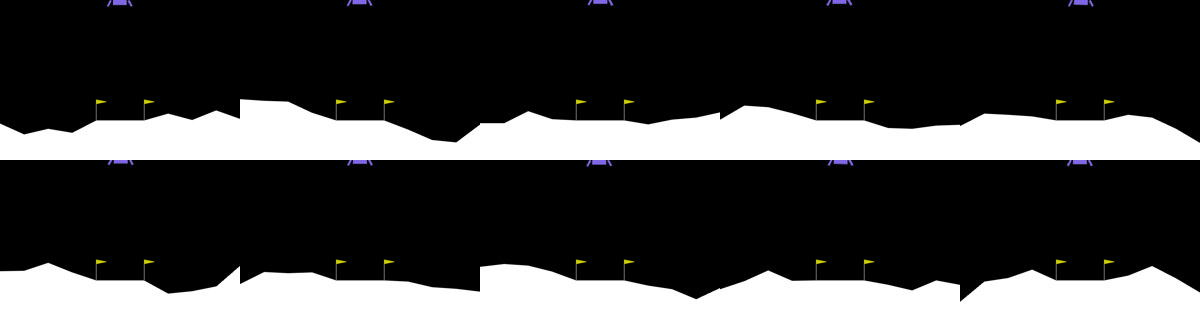

In [19]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


### TODO 2: cortes de la política

Se usan los pesos guardados del agente completo de semilla 42, los mismos de la
figura de cortes del informe. Se parte del estado de referencia
$x=v_x=\theta=\omega=c_1=c_2=0$, $y=0{,}8$, $v_y=-0{,}3$ y en cada corte se mueven
solo dos variables. El color muestra la acción que elige la red en cada punto.

In [20]:
NOMBRES_ACCIONES = ['nada', 'motor izquierdo', 'motor principal', 'motor derecho']
COLORES = ListedColormap(['#bbbbbb', '#e69f00', '#009e73', '#0072b2'])
ESTADO_REFERENCIA = np.array([0, 0.8, 0, -0.3, 0, 0, 0, 0], dtype=np.float32)

# Cada corte: (variable del eje x, variable del eje y, rango x, rango y, nombre x, nombre y)
CORTES = [
    (0, 2, (-1, 1), (-1.5, 1.5), 'x', 'vx'),
    (4, 5, (-0.7, 0.7), (-1.5, 1.5), 'θ', 'ω'),
    (1, 3, (0.1, 1.5), (-2, 1), 'y', 'vy'),
]


def cargar_red(semilla):
    """Arma la red 8 -> 64 -> 64 -> 4 y le carga los pesos guardados de esa semilla."""
    red = nn.Sequential(nn.Linear(8, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 4))
    texto = datos['pesos_completo'][str(semilla)]
    archivo = io.BytesIO(base64.b64decode(texto))
    pesos = torch.load(archivo, map_location='cpu', weights_only=True)
    red.load_state_dict(pesos)
    return red


def acciones_del_corte(red, corte):
    """Devuelve la grilla de valores y la acción que elige la red en cada punto."""
    ix, iy, rango_x, rango_y, _, _ = corte
    valores_x = np.linspace(rango_x[0], rango_x[1], 101)
    valores_y = np.linspace(rango_y[0], rango_y[1], 101)
    grilla_x, grilla_y = np.meshgrid(valores_x, valores_y)

    # Todos los estados empiezan iguales al de referencia y se cambian solo dos valores
    estados = np.tile(ESTADO_REFERENCIA, (grilla_x.size, 1))
    estados[:, ix] = grilla_x.ravel()
    estados[:, iy] = grilla_y.ravel()

    with torch.no_grad():
        valores_q = red(torch.tensor(estados)).numpy()
    acciones = valores_q.argmax(axis=1).reshape(101, 101)
    return valores_x, valores_y, acciones


def dibujar_corte(ax, red, corte, titulo):
    valores_x, valores_y, acciones = acciones_del_corte(red, corte)
    ax.pcolormesh(valores_x, valores_y, acciones, cmap=COLORES, vmin=-0.5, vmax=3.5, shading='auto')
    ax.set_xlabel(corte[4])
    ax.set_ylabel(corte[5])
    ax.set_title(titulo)


def agregar_leyenda(fig):
    cuadros = []
    for i in range(4):
        cuadros.append(Patch(color=COLORES(i), label=NOMBRES_ACCIONES[i]))
    fig.legend(handles=cuadros, loc='lower center', ncol=4, frameon=False)

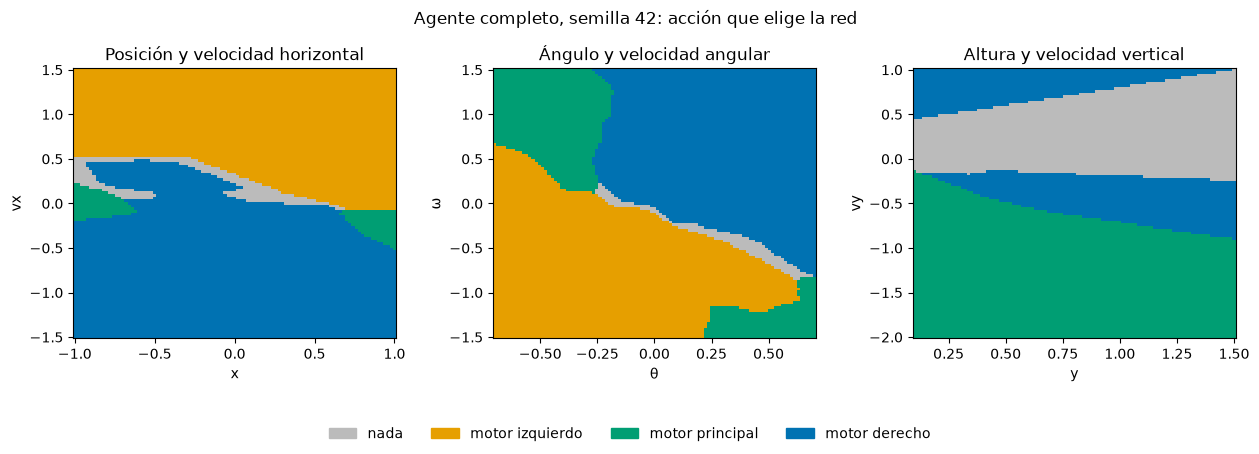

In [21]:
# Los tres cortes del agente completo, semilla 42
red_42 = cargar_red(42)
titulos = ['Posición y velocidad horizontal', 'Ángulo y velocidad angular', 'Altura y velocidad vertical']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for i in range(3):
    dibujar_corte(ejes[i], red_42, CORTES[i], titulos[i])
agregar_leyenda(fig)
fig.suptitle('Agente completo, semilla 42: acción que elige la red')
fig.subplots_adjust(bottom=0.25, top=0.85, wspace=0.3)
plt.show()

El mismo corte del ángulo para las ocho semillas del agente completo, para ver si
la organización se repite:

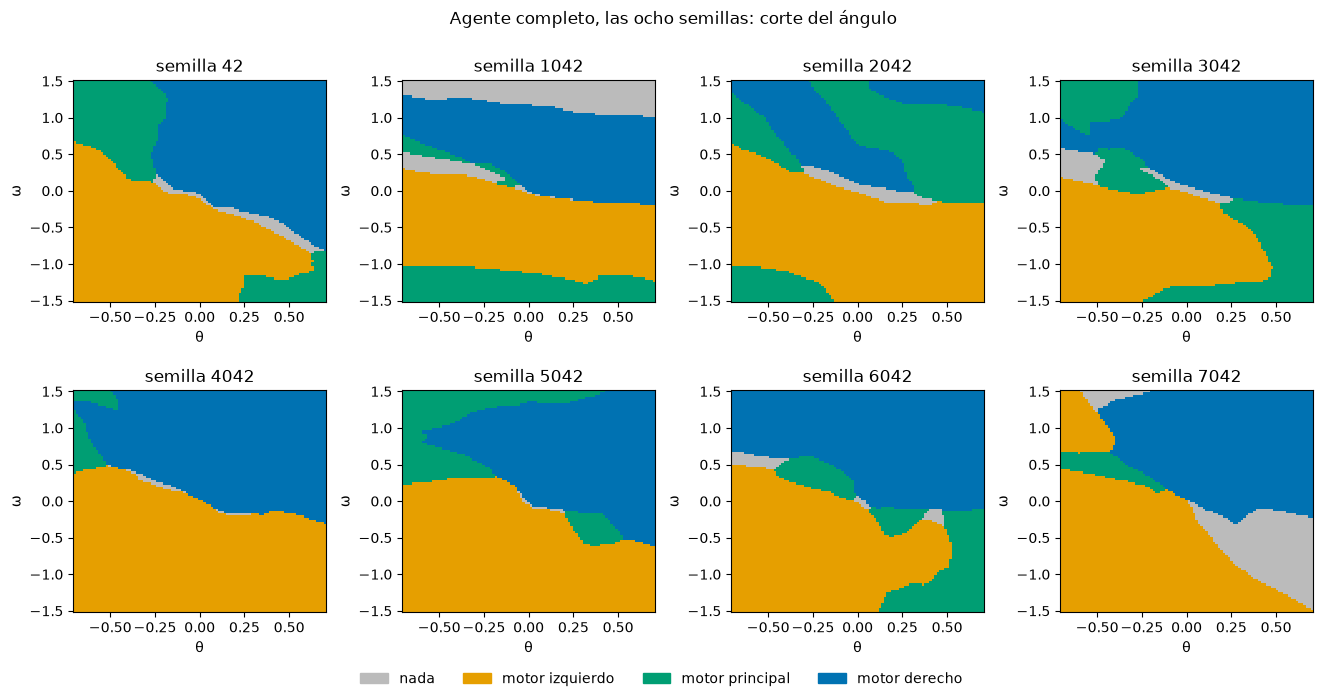

In [22]:
SEMILLAS = [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]

fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for i in range(8):
    semilla = SEMILLAS[i]
    fila = i // 4
    columna = i % 4
    red = cargar_red(semilla)
    dibujar_corte(ejes[fila][columna], red, CORTES[1], f'semilla {semilla}')
agregar_leyenda(fig)
fig.suptitle('Agente completo, las ocho semillas: corte del ángulo')
fig.subplots_adjust(bottom=0.12, hspace=0.4, wspace=0.3)
plt.show()

### Cómo terminan los episodios

Las 32 redes del estudio se evaluaron de nuevo en 20 escenarios cada una (10000 a
10019); esta evaluación extra se hizo en macOS. Un final cuenta como posado si el
episodio termina con $+100$ en el último paso. Los demás finales son choques o
salidas de la zona, y los truncados son los que llegan a los 1000 pasos.

In [23]:
NOMBRES = {'full': 'Completo', 'no_target': 'Sin red objetivo',
           'no_replay': 'Sin replay', 'no_exploration': 'Sin exploración'}
VARIANTES = ['full', 'no_target', 'no_replay', 'no_exploration']

print('Condición        | Posado | Choque/salida | Truncado | R >= 200')
for variante in VARIANTES:
    posados = 0
    choques = 0
    truncados = 0
    exitos = 0
    for agente in datos['finales']:
        if agente['variante'] != variante:
            continue
        for episodio in agente['episodios']:
            if episodio['fin'] == 'posado':
                posados += 1
            elif episodio['fin'] == 'choque':
                choques += 1
            else:
                truncados += 1
            if episodio['recompensa'] >= UMBRAL_EXITO:
                exitos += 1
    print(f"{NOMBRES[variante]:16s} | {posados:6d} | {choques:13d} | {truncados:8d} | {exitos:8d}")

Condición        | Posado | Choque/salida | Truncado | R >= 200
Completo         |    105 |             7 |       48 |       68
Sin red objetivo |     66 |            54 |       40 |       44
Sin replay       |     22 |           135 |        3 |       21
Sin exploración  |     35 |            48 |       77 |       27


## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


### TODO 3: estudio de ablación

Se compara el agente completo contra tres variantes que quitan una sola parte: sin
red objetivo, sin replay y sin exploración (sección VI del informe). Cada condición
tiene ocho semillas de entrenamiento (42, 1042, …, 7042), se entrena 300 episodios y
se evalúa sin explorar en los escenarios 10000 a 10199. Cada agente entrenado cuenta
como un solo dato: el promedio de sus 200 episodios de evaluación.

Para comparar cada variante con el agente completo se usa el test U de Mann–Whitney
bilateral exacto, y los tres valores $p$ se corrigen con el método de Holm
($\alpha = 0{,}05$).

In [24]:
# Retorno medio de evaluación de cada agente: medias[variante][semilla]
medias = {}
for corrida in datos['corridas']:
    variante = corrida['variante']
    if variante not in medias:
        medias[variante] = {}
    medias[variante][corrida['semilla']] = np.mean(corrida['evaluacion'])

print('Semilla | Completo | Sin objetivo | Sin replay | Sin explor.')
for semilla in SEMILLAS:
    fila = f'{semilla:7d}'
    for variante in VARIANTES:
        fila += f' | {medias[variante][semilla]:8.1f}'
    print(fila)

print()
for variante in VARIANTES:
    valores = list(medias[variante].values())
    exitos = 0
    for corrida in datos['corridas']:
        if corrida['variante'] == variante:
            retornos = np.array(corrida['evaluacion'])
            exitos += int((retornos >= UMBRAL_EXITO).sum())
    print(f"{NOMBRES[variante]:16s}: media {np.mean(valores):6.1f} | DE {np.std(valores, ddof=1):6.1f} "
          f"| éxitos {exitos}/1600 ({exitos / 1600:.2%})")

Semilla | Completo | Sin objetivo | Sin replay | Sin explor.
     42 |    174.9 |    140.3 |    -28.2 |   -168.7
   1042 |    183.2 |   -211.9 |    122.8 |     62.6
   2042 |     80.6 |    189.3 |      6.2 |    150.7
   3042 |     69.5 |     20.6 |   -129.5 |    -70.2
   4042 |     60.5 |      0.7 |   -129.2 |   -133.3
   5042 |    121.9 |     81.7 |    107.6 |     65.9
   6042 |    203.2 |    149.7 |     38.3 |    119.2
   7042 |    208.7 |      7.0 |      5.1 |    180.3

Completo        : media  137.8 | DE   62.0 | éxitos 647/1600 (40.44%)
Sin red objetivo: media   47.2 | DE  126.6 | éxitos 352/1600 (22.00%)
Sin replay      : media   -0.8 | DE   94.5 | éxitos 189/1600 (11.81%)
Sin exploración : media   25.8 | DE  132.8 | éxitos 287/1600 (17.94%)


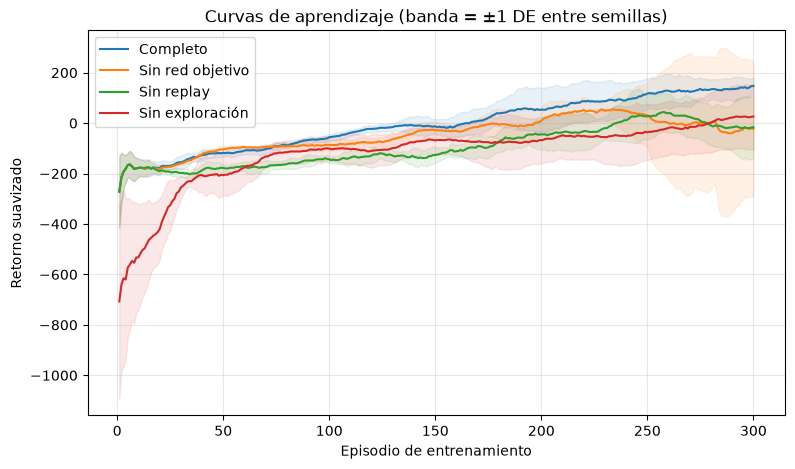

Completo: primeros 20 episodios -177.6, últimos 20 episodios 147.0


In [25]:
# Curvas de entrenamiento: media móvil de 20 episodios, promediada sobre las 8 semillas
episodios = np.arange(1, 301)
fig, ax = plt.subplots(figsize=(9, 5))
for variante in VARIANTES:
    curvas = []
    for corrida in datos['corridas']:
        if corrida['variante'] == variante:
            curvas.append(media_movil(corrida['entrenamiento'], ventana=20))
    curvas = np.array(curvas)
    media = curvas.mean(axis=0)
    desvio = curvas.std(axis=0, ddof=1)
    linea = ax.plot(episodios, media, label=NOMBRES[variante])[0]
    ax.fill_between(episodios, media - desvio, media + desvio, color=linea.get_color(), alpha=0.1)

ax.set_xlabel('Episodio de entrenamiento')
ax.set_ylabel('Retorno suavizado')
ax.set_title('Curvas de aprendizaje (banda = ±1 DE entre semillas)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Retorno promedio de los primeros y los últimos 20 episodios del agente completo
completo_entrenamiento = []
for corrida in datos['corridas']:
    if corrida['variante'] == 'full':
        completo_entrenamiento.append(corrida['entrenamiento'])
completo_entrenamiento = np.array(completo_entrenamiento)
print(f"Completo: primeros 20 episodios {completo_entrenamiento[:, :20].mean():.1f}, "
      f"últimos 20 episodios {completo_entrenamiento[:, -20:].mean():.1f}")

In [26]:
def holm(p_valores):
    """Corrección de Holm: ordena los p de menor a mayor y los multiplica por 3, 2 y 1."""
    m = len(p_valores)
    orden = np.argsort(p_valores)
    ajustados = [0.0] * m
    maximo = 0.0
    for posicion in range(m):
        i = orden[posicion]
        valor = min(1.0, (m - posicion) * p_valores[i])
        maximo = max(maximo, valor)   # un p ajustado nunca puede ser menor que el anterior
        ajustados[i] = maximo
    return ajustados


completo = []
for semilla in SEMILLAS:
    completo.append(medias['full'][semilla])

p_valores = []
filas = []
for variante in ['no_target', 'no_replay', 'no_exploration']:
    ablacion = []
    for semilla in SEMILLAS:
        ablacion.append(medias[variante][semilla])
    resultado = stats.mannwhitneyu(completo, ablacion, alternative='two-sided', method='exact')
    diferencia = np.mean(completo) - np.mean(ablacion)
    p_valores.append(resultado.pvalue)
    filas.append((variante, diferencia, resultado.statistic))

p_holm = holm(p_valores)

print('Ablación         | Δ media |  U | p MW   | p Holm | ¿Significativo?')
for i in range(3):
    variante, diferencia, u = filas[i]
    if p_holm[i] < 0.05:
        significativo = 'sí'
    else:
        significativo = 'no'
    print(f"{NOMBRES[variante]:16s} | {diferencia:7.1f} | {u:2.0f} | {p_valores[i]:.4f} | {p_holm[i]:.4f} | {significativo}")
print('\nΔ media: retorno medio del completo menos el de la ablación. U corresponde al completo.')

Ablación         | Δ media |  U | p MW   | p Holm | ¿Significativo?
Sin red objetivo |    90.6 | 47 | 0.1304 | 0.1304 | no
Sin replay       |   138.7 | 57 | 0.0070 | 0.0210 | sí
Sin exploración  |   112.0 | 50 | 0.0650 | 0.1299 | no

Δ media: retorno medio del completo menos el de la ablación. U corresponde al completo.
